# Scania Trucks APS Failure 
# ( phronesis final project )

# IMPORT LIBRARIES 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay)
import joblib
from fastapi import FastAPI
from pydantic import BaseModel
import uvicorn
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("All project libraries are ready.")

# Define the dataset path

In [9]:
DATA_PATH = Path("aps_failure_training_set.csv")
print("Dataset exists:", DATA_PATH.exists())

Dataset exists: True


# Load the dataset

In [10]:
df = pd.read_csv(DATA_PATH, na_values="na")
df["class"] = df["class"].map({"neg": 0, "pos": 1})
df.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,ap_000,aq_000,ar_000,as_000,at_000,au_000,av_000,ax_000,ay_000,ay_001,ay_002,ay_003,ay_004,ay_005,ay_006,ay_007,ay_008,ay_009,az_000,az_001,az_002,az_003,az_004,az_005,az_006,az_007,az_008,az_009,ba_000,ba_001,ba_002,ba_003,ba_004,ba_005,ba_006,ba_007,ba_008,ba_009,bb_000,bc_000,bd_000,be_000,bf_000,bg_000,bh_000,bi_000,bj_000,bk_000,bl_000,bm_000,bn_000,bo_000,bp_000,bq_000,br_000,bs_000,bt_000,bu_000,bv_000,bx_000,by_000,bz_000,ca_000,cb_000,cc_000,cd_000,ce_000,cf_000,cg_000,ch_000,ci_000,cj_000,ck_000,cl_000,cm_000,cn_000,cn_001,cn_002,cn_003,cn_004,cn_005,cn_006,cn_007,cn_008,cn_009,co_000,cp_000,cq_000,cr_000,cs_000,cs_001,cs_002,cs_003,cs_004,cs_005,cs_006,cs_007,cs_008,cs_009,ct_000,cu_000,cv_000,cx_000,cy_000,cz_000,da_000,db_000,dc_000,dd_000,de_000,df_000,dg_000,dh_000,di_000,dj_000,dk_000,dl_000,dm_000,dn_000,do_000,dp_000,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,0.0,0.0,4933296.0,3655166.0,1766008.0,1132040.0,0.0,0.0,0.0,0.0,1012.0,268.0,0.0,0.0,0.0,0.0,0.0,469014.0,4239660.0,703300.0,755876.0,0.0,5374.0,2108.0,4114.0,12348.0,615248.0,5526276.0,2378.0,4.0,0.0,0.0,2328746.0,1022304.0,415432.0,287230.0,310246.0,681504.0,1118814.0,3574.0,0.0,0.0,6700214.0,0.0,10.0,108.0,50.0,2551696.0,97518.0,947550.0,799478.0,330760.0,353400.0,299160.0,305200.0,283680.0,NaN,NaN,NaN,178540.0,76698.08,6700214.0,6700214.0,6599892.0,43566.0,68656.0,54064.0,638360.0,6167850.0,1209600.0,246244.0,2.0,96.0,0.0,5245752.00,0.0,916567.68,6.0,1924.0,0.0,0.0,0.0,118196.0,1309472.0,3247182.0,1381362.0,98822.0,11208.0,1608.0,220.0,240.0,6700214.0,NaN,10476.0,1226.0,267998.0,521832.0,428776.0,4015854.0,895240.0,26330.0,118.0,0.0,532.0,734.0,4122704.0,51288.0,0.0,532572.0,0.0,18.0,5330690.0,4732.0,1126.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62282.0,85908.0,32790.0,0.0,0.0,202710.0,37928.0,14745580.0,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,0,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,0.0,0.0,2560898.0,2127150.0,1084598.0,338544.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,71510.0,772720.0,1996924.0,99560.0,0.0,7336.0,7808.0,13776.0,13086.0,1010074.0,1873902.0,14726.0,6.0,0.0,0.0,1378576.0,447166.0,199512.0,154298.0,137280.0,138668.0,165908.0,229652.0,87082.0,4708.0,3646660.0,86.0,454.0,364.0,350.0,1393352.0,49028.0,688314.0,392208.0,341420.0,359780.0,366560.0,NaN,NaN,NaN,NaN,NaN,6700.0,33057.51,3646660.0,3646660.0,3582034.0,17733.0,260120.0,115626.0,6900.0,2942850.0,1209600.0,0.0,NaN,NaN,NaN,2291079.36,0.0,643536.96,0.0,0.0,0.0,0.0,38.0,98644.0,1179502.0,1286736.0,336388.0,36294.0,5192.0,56.0,NaN,0.0,3646660.0,NaN,6160.0,796.0,164860.0,350066.0,272956.0,1837600.0,301242.0,9148.0,22.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3312.0,522.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33736.0,36946.0,5936.0,0.0,0.0,103330.0,16254.0,4510080.0,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,0,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,0.0,0.0,2371990.0,2173634.0,300796.0,153698.0,0.0,0.0,0.0,0.0,358.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,870456.0,239798.0,1450312.0,0.0,1620.0,1156.0,1228.0,34250.0,1811606.0,710672.0,34.0,0.0,0.0,0.0,790690.0,672026.0,332340.0,254892.0,189596.0,135758.0,103552.0,81666.0,46.0,0.0,2673338.0,128.0,202.0,576.0,4.0,1234132.0,28804.0,160176.0,139730.0,137160.0,130640.0,Na

# Display the number of rows and columns

In [12]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 60000
Number of columns: 171


# Display all column names

In [13]:
print(df.columns.tolist()[:20])

['class', 'aa_000', 'ab_000', 'ac_000', 'ad_000', 'ae_000', 'af_000', 'ag_000', 'ag_001', 'ag_002', 'ag_003', 'ag_004', 'ag_005', 'ag_006', 'ag_007', 'ag_008', 'ag_009', 'ah_000', 'ai_000', 'aj_000']


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 171 entries, class to eg_000
dtypes: float64(169), int64(2)
memory usage: 78.3 MB


In [15]:
df.describe()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,ap_000,aq_000,ar_000,as_000,at_000,au_000,av_000,ax_000,ay_000,ay_001,ay_002,ay_003,ay_004,ay_005,ay_006,ay_007,ay_008,ay_009,az_000,az_001,az_002,az_003,az_004,az_005,az_006,az_007,az_008,az_009,ba_000,ba_001,ba_002,ba_003,ba_004,ba_005,ba_006,ba_007,ba_008,ba_009,bb_000,bc_000,bd_000,be_000,bf_000,bg_000,bh_000,bi_000,bj_000,bk_000,bl_000,bm_000,bn_000,bo_000,bp_000,bq_000,br_000,bs_000,bt_000,bu_000,bv_000,bx_000,by_000,bz_000,ca_000,cb_000,cc_000,cd_000,ce_000,cf_000,cg_000,ch_000,ci_000,cj_000,ck_000,cl_000,cm_000,cn_000,cn_001,cn_002,cn_003,cn_004,cn_005,cn_006,cn_007,cn_008,cn_009,co_000,cp_000,cq_000,cr_000,cs_000,cs_001,cs_002,cs_003,cs_004,cs_005,cs_006,cs_007,cs_008,cs_009,ct_000,cu_000,cv_000,cx_000,cy_000,cz_000,da_000,db_000,dc_000,dd_000,de_000,df_000,dg_000,dh_000,di_000,dj_000,dk_000,dl_000,dm_000,dn_000,do_000,dp_000,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
count,60000.000000,6.000000e+04,13671.000000,5.666500e+04,4.513900e+04,57500.000000,57500.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.935500e+04,5.937100e+04,5.937100e+04,5.560000e+04,5.935800e+04,5.937100e+04,5.935800e+04,5.941100e+04,5.935800e+04,5.941100e+04,57277.000000,5.937100e+04,5.937100e+04,5.937100e+04,57500.000000,57499.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,59329.000000,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.931200e+04,5.935500e+04,57275.000000,57273.000000,57497.000000,57500.000000,5.935800e+04,5.935800e+04,5.941100e+04,5.941100e+04,3.696600e+04,3.272300e+04,2.045100e+04,1.599100e+04,1.366700e+04,1.226000e+04,1.127800e+04,1.073600e+04,5.927400e+04,5.983300e+04,5.930900e+04,5.930900e+04,5.674300e+04,5.952700e+04,5.727700e+04,55644.000000,5.927400e+04,5.674500e+04,59324.0,5.749800e+04,4.513900e+04,45139.000000,45139.000000,5.966200e+04,5.966200e+04,5.966200e+04,50447.000000,50123.000000,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,5.931300e+04,4.513900e+04,57276.000000,5.930900e+04,13671.000000,59331.000000,59331.000000,5.933100e+04,5.933100e+04,5.933100e+04,5.933100e+04,5.933100e+04,5.933100e+04,5.933100e+04,5.933100e+04,46192.000000,46192.000000,4.619200e+04,4.619200e+04,46192.000000,4.619200e+04,46192.000000,46192.000000,4.619200e+04,57497.000000,57276.000000,5.599200e+04,5.599200e+04,5.599200e+04,5.599400e+04,55993.000000,5.599300e+04,5.599200e+04,5.599100e+04,5.930900e+04,5.727600e+04,57274.000000,5.727400e+04,5.727400e+04,5.727300e+04,57273.000000,5.727400e+04,5.727400e+04,5.727700e+04,5.727600e+04,57277.000000,57277.000000,5.599300e+04,49761.000000,50447.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,57276.000000,57277.000000
mean,0.016667,5.933650e+04,0.713189,3.560143e+08,1.906206e+05,6.819130,11.006817,2.216364e+02,9.757223e+02,8.606015e+03,8.859128e+04,4.370966e+05,1.108374e+06,1.657818e+06,4.993098e+05,3.556989e+04,5.114753e+03,1.809931e+06,9.016965e+03,1.143675e+03,9.794900e+02,5.913048e+04,9.328133e+04,3.461037e+06,3.002440e+06,1.004160e+06,4.424045e+05,0.496918,1.267365e+02,5.072046e+03,2.305804e+02,1117.825913,374.327380,1.221165e+04,1.019012e+04,1.097500e+04,7.225784e+03,1.056600e+04,1.119791e+05,1.078551e+06,1.546032e+06,1.051123e+06,1.162622e+03,7.849608e+03,4.420992e+03,8.066082e+03,8

# Count missing values in each column

In [16]:
missing_values = df.isnull().sum()
print(missing_values.sort_values(ascending=False).head(15))

br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
ab_000    46329
cr_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034
ch_000    14861
co_000    14861
cg_000    14861
cf_000    14861
ad_000    14861
dtype: int64


# Calculate missing-value percentages

In [17]:
missing_percent = (df.isnull().mean() * 100).round(2)
print(missing_percent.sort_values(ascending=False).head(15))

br_000    82.11
bq_000    81.20
bp_000    79.57
ab_000    77.22
cr_000    77.22
bo_000    77.22
bn_000    73.35
bm_000    65.92
bl_000    45.46
bk_000    38.39
ch_000    24.77
co_000    24.77
cg_000    24.77
cf_000    24.77
ad_000    24.77
dtype: float64


# Count duplicate rows

In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


# Data Understanding
# 1. Define the target column

In [19]:
TARGET = "class"

print("Target distribution:")
print(df[TARGET].value_counts())

print("\nTarget percentages:")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

Target distribution:
class
0    59000
1     1000
Name: count, dtype: int64

Target percentages:
class
0    98.33
1     1.67
Name: proportion, dtype: float64


# 2. Visualize APS failure status distribution

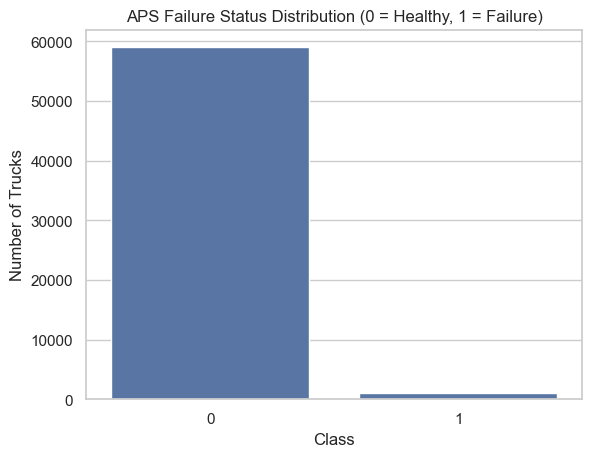

In [20]:
sns.countplot(data=df, x=TARGET)

plt.title("APS Failure Status Distribution (0 = Healthy, 1 = Failure)")
plt.xlabel("Class")
plt.ylabel("Number of Trucks")
plt.show()

# Count and plot top 15 columns with missing values

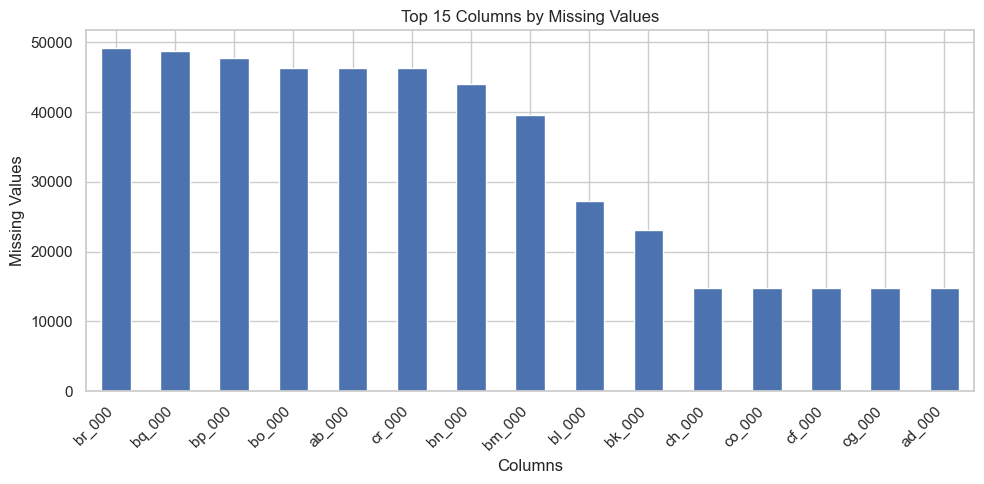

In [21]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False).head(15)

missing.plot(kind="bar", figsize=(10, 5))

plt.title("Top 15 Columns by Missing Values")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Plot sensor aa_000 distribution

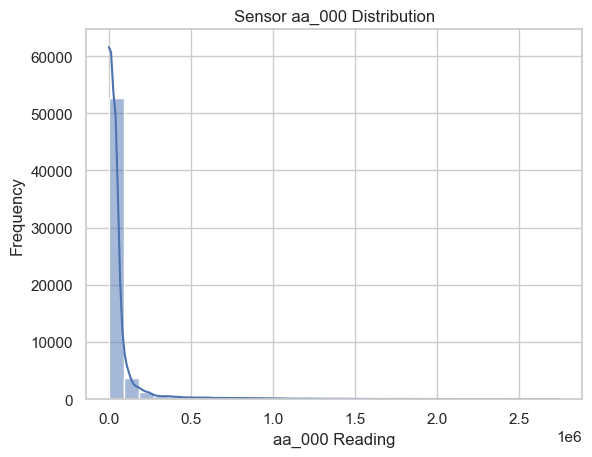

In [22]:
sns.histplot(data=df, x="aa_000", bins=30, kde=True)

plt.title("Sensor aa_000 Distribution")
plt.xlabel("aa_000 Reading")
plt.ylabel("Frequency")
plt.show()

# Sensor aa_000 versus APS failure status

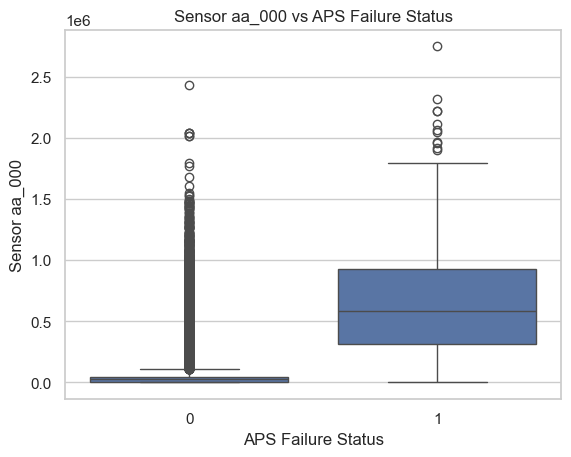

In [23]:
sns.boxplot(data=df, x=TARGET, y="aa_000")

plt.title("Sensor aa_000 vs APS Failure Status")
plt.xlabel("APS Failure Status")
plt.ylabel("Sensor aa_000")
plt.show()

# Data Cleaning & Feature Engineering

# 1. Drop columns with > 50% missing values

In [24]:
high_missing_cols = df.columns[df.isnull().mean() > 0.50].tolist()
df_clean = df.drop(columns=high_missing_cols).copy()

# 2. Engineer new features before splitting

In [25]:
sensor_cols = [col for col in df_clean.columns if col != TARGET]
df_clean["missing_sensor_count"] = df_clean[sensor_cols].isnull().sum(axis=1)
df_clean["sensor_mean"] = df_clean[sensor_cols].mean(axis=1)
df_clean["sensor_std"] = df_clean[sensor_cols].std(axis=1)

# 3. Handle outliers by clipping between 1st and 99th percentiles

In [26]:
num_cols = [col for col in df_clean.columns if col != TARGET]
lower_bound = df_clean[num_cols].quantile(0.01)
upper_bound = df_clean[num_cols].quantile(0.99)
df_clean[num_cols] = df_clean[num_cols].clip(lower=lower_bound, upper=upper_bound, axis=1)

In [27]:
print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (60000, 166)


# Missing sensor count versus APS failure status

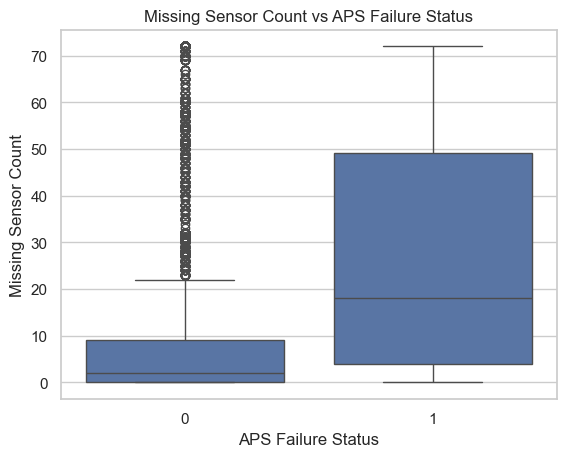

In [28]:
sns.boxplot(data=df_clean, x=TARGET, y="missing_sensor_count")

plt.title("Missing Sensor Count vs APS Failure Status")
plt.xlabel("APS Failure Status")
plt.ylabel("Missing Sensor Count")
plt.show()

# Data Preprocessing
# Separate features and target

In [29]:
TARGET = "class"

correlations = df_clean.corr()[TARGET].abs().sort_values(ascending=False)
top_features = correlations.drop(TARGET).head(20).index.tolist()

X = df_clean[top_features]
y = df_clean[TARGET]

print("Selected Top 20 Features:", top_features)
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

Selected Top 20 Features: ['bj_000', 'aq_000', 'ci_000', 'dn_000', 'ap_000', 'bb_000', 'bv_000', 'bu_000', 'cq_000', 'ck_000', 'bt_000', 'aa_000', 'bh_000', 'ah_000', 'cc_000', 'bg_000', 'an_000', 'bx_000', 'ao_000', 'cs_002']
Features shape: (60000, 20)
Target shape: (60000,)
Target classes: [np.int64(0), np.int64(1)]


# Split data into training and testing sets

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 48000
Testing samples: 12000


# Identify numerical columns and build preprocessor

In [31]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)])

print("Numerical features count:", len(numeric_features))
print("Complete preprocessor is ready.")

Numerical features count: 20
Complete preprocessor is ready.


# Model 1: Logistic Regression

In [32]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))])

logistic_model.fit(X_train, y_train)
y_pred = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Logistic Regression Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Logistic Regression Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("Logistic Regression F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Logistic Regression Accuracy: 0.964
Logistic Regression Precision: 0.3073
Logistic Regression Recall: 0.925
Logistic Regression F1 Score: 0.4613

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     11800
           1       0.31      0.93      0.46       200

    accuracy                           0.96     12000
   macro avg       0.65      0.94      0.72     12000
weighted avg       0.99      0.96      0.97     12000



# Plot confusion matrix

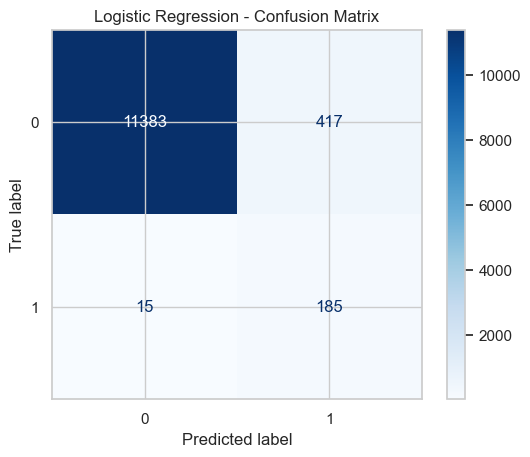

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Model 2: Decision Tree

In [34]:
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42))])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("Decision Tree Accuracy:", round(accuracy_score(y_test, tree_pred), 4))
print("Decision Tree F1 Score:", round(f1_score(y_test, tree_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, tree_pred, zero_division=0))

Decision Tree Accuracy: 0.9577
Decision Tree F1 Score: 0.424

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     11800
           1       0.27      0.94      0.42       200

    accuracy                           0.96     12000
   macro avg       0.64      0.95      0.70     12000
weighted avg       0.99      0.96      0.97     12000



# Model 3: Random Forest (Ensemble)

In [35]:
forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1))])

forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

print("Random Forest Accuracy:", round(accuracy_score(y_test, forest_pred), 4))
print("Random Forest F1 Score:", round(f1_score(y_test, forest_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, forest_pred, zero_division=0))

Random Forest Accuracy: 0.9888
Random Forest F1 Score: 0.5872

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     11800
           1       0.76      0.48      0.59       200

    accuracy                           0.99     12000
   macro avg       0.87      0.74      0.79     12000
weighted avg       0.99      0.99      0.99     12000



# Model 4: Voting Classifier (Ensemble)

In [36]:
voting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
            ("dt", DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42)),
            ("rf", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1))
        ],
        voting="soft"
    ))])

voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)

print("Voting Classifier Accuracy:", round(accuracy_score(y_test, voting_pred), 4))
print("Voting Classifier F1 Score:", round(f1_score(y_test, voting_pred, zero_division=0), 4))

Voting Classifier Accuracy: 0.9707
Voting Classifier F1 Score: 0.5125


# Compare Models Performance

In [37]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Voting Ensemble"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, forest_pred),
        accuracy_score(y_test, voting_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, tree_pred, zero_division=0),
        f1_score(y_test, forest_pred, zero_division=0),
        f1_score(y_test, voting_pred, zero_division=0)
    ]
})

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print(results.round(4))

                 Model  Accuracy  F1 Score
0        Random Forest    0.9888    0.5872
1      Voting Ensemble    0.9707    0.5125
2  Logistic Regression    0.9640    0.4613
3        Decision Tree    0.9577    0.4240


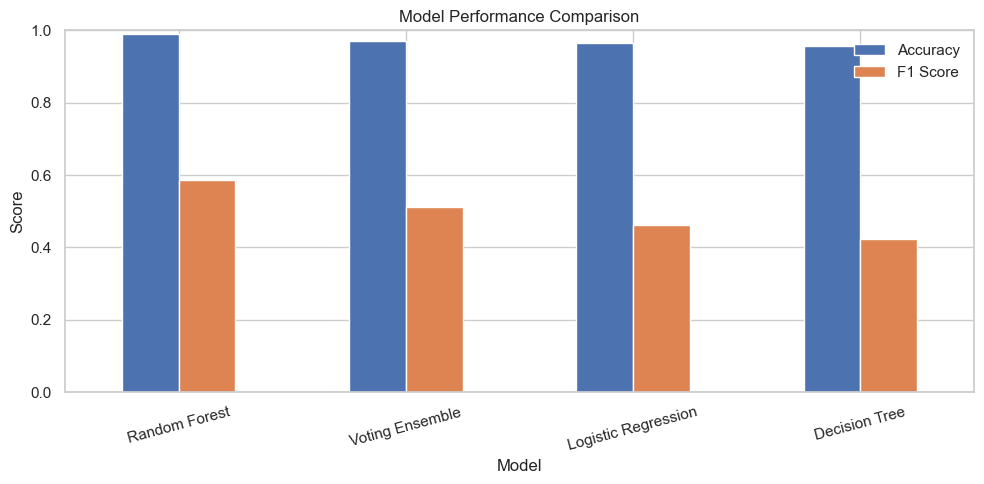

In [38]:
results.set_index("Model")[["Accuracy", "F1 Score"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Hyperparameter Tuning (GridSearchCV)

In [39]:
param_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__max_depth": [10, 15]
}

grid_search = GridSearchCV(
    forest_model,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Tuned Random Forest Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Tuned Random Forest F1 Score:", round(f1_score(y_test, best_pred, zero_division=0), 4))

Best Parameters: {'classifier__max_depth': 15, 'classifier__n_estimators': 100}
Tuned Random Forest Accuracy: 0.9813
Tuned Random Forest F1 Score: 0.5867


# Plot Confusion Matrix and ROC Curve for the Best Model

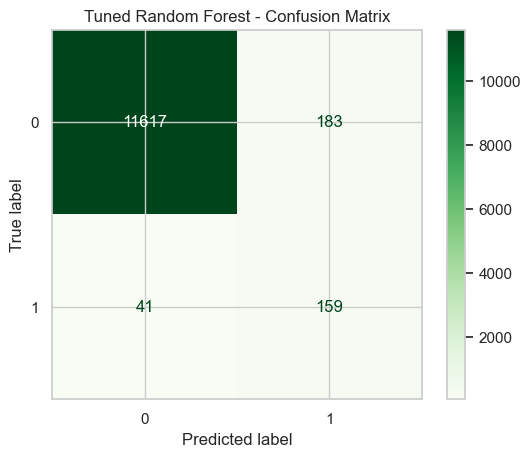

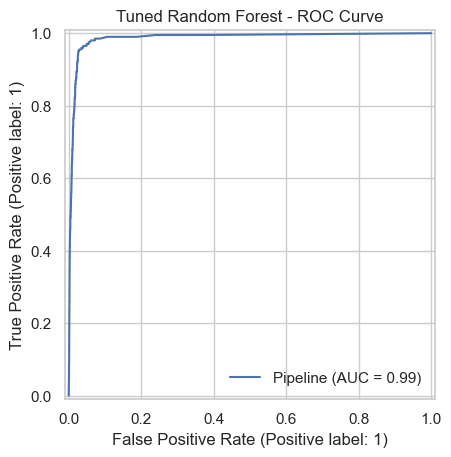

In [47]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    cmap="Greens"
)
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Tuned Random Forest - ROC Curve")
plt.show()

# Plot Top 10 Most Important Features

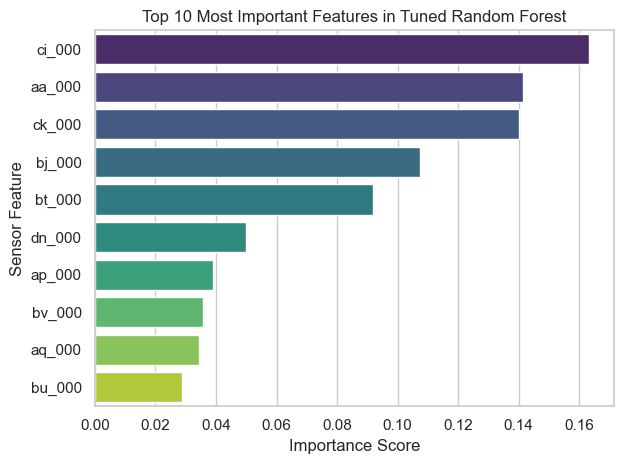

In [50]:
importances = best_model.named_steps["classifier"].feature_importances_
feature_imp_df = pd.DataFrame({
    "Feature": top_features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).head(10)

sns.barplot(data=feature_imp_df, x="Importance", y="Feature", palette="viridis")

plt.title("Top 10 Most Important Features in Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Sensor Feature")
plt.tight_layout()
plt.show()

# Evaluate on the Official Scania Test Set (aps_failure_test_set.csv)

In [48]:
TEST_PATH = Path("aps_failure_test_set.csv")

if TEST_PATH.exists():
    test_official = pd.read_csv(TEST_PATH, na_values="na")
    test_official["class"] = test_official["class"].map({"neg": 0, "pos": 1})
    
    test_official["missing_sensor_count"] = test_official[sensor_cols].isnull().sum(axis=1)
    test_official["sensor_mean"] = test_official[sensor_cols].mean(axis=1)
    test_official["sensor_std"] = test_official[sensor_cols].std(axis=1)
    
    X_official = test_official[top_features]
    y_official = test_official["class"]
    
    official_pred = best_model.predict(X_official)
    
    print("Official Test Set Accuracy:", round(accuracy_score(y_official, official_pred), 4))
    print("Official Test Set F1 Score:", round(f1_score(y_official, official_pred, zero_division=0), 4))
    print("\nOfficial Test Classification Report:")
    print(classification_report(y_official, official_pred, zero_division=0))

Official Test Set Accuracy: 0.9804
Official Test Set F1 Score: 0.6416

Official Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     15625
           1       0.56      0.75      0.64       375

    accuracy                           0.98     16000
   macro avg       0.78      0.87      0.82     16000
weighted avg       0.98      0.98      0.98     16000



# Save the Final Pipeline with joblib

In [41]:
MODEL_PATH = Path("scania_aps_pipeline.joblib")
joblib.dump(best_model, MODEL_PATH)

print("Saved model exists:", MODEL_PATH.exists())

Saved model exists: True


# Build and Test FastAPI App (/predict endpoint)

In [43]:
from fastapi.testclient import TestClient

app = FastAPI(title="Scania APS Failure Prediction API")
loaded_model = joblib.load("scania_aps_pipeline.joblib")

class TruckData(BaseModel):
    features: dict

@app.get("/")
def home():
    return {"message": "Scania APS Failure Prediction API is running"}

@app.post("/predict")
def predict(data: TruckData):
    input_df = pd.DataFrame([data.features])
    prediction = int(loaded_model.predict(input_df)[0])
    probability = float(loaded_model.predict_proba(input_df)[0][1])
    return {
        "prediction": prediction,
        "status": "APS Failure (pos)" if prediction == 1 else "Healthy (neg)",
        "failure_probability": round(probability, 4)
    }

client = TestClient(app)
sample_truck = X_test.iloc[0].to_dict()
response = client.post("/predict", json={"features": sample_truck})

print("API Status Code:", response.status_code)
print("API Response:", response.json())

API Status Code: 200
API Response: {'prediction': 0, 'status': 'Healthy (neg)', 'failure_probability': 0.0}


# Save Standalone FastAPI Server File (app.py) for Local Deployment

In [46]:
app_code = """
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(title="Scania APS Failure Prediction API")
model = joblib.load("scania_aps_pipeline.joblib")

class TruckData(BaseModel):
    features: dict

@app.get("/")
def home():
    return {"message": "Scania APS Failure Prediction API is running"}

@app.post("/predict")
def predict(data: TruckData):
    df_input = pd.DataFrame([data.features])
    pred = int(model.predict(df_input)[0])
    prob = float(model.predict_proba(df_input)[0][1])
    return {
        "prediction": pred,
        "status": "APS Failure (pos)" if pred == 1 else "Healthy (neg)",
        "failure_probability": round(prob, 4)
    }
"""

with open("app.py", "w") as f:
    f.write(app_code.strip())

print("app.py created successfully. Run 'uvicorn app:app --reload' in terminal to start the live server.")

app.py created successfully. Run 'uvicorn app:app --reload' in terminal to start the live server.


# Start the Live FastAPI Server in Background and Test with httpx

In [56]:
import threading
import time
import socket
import httpx

sock = socket.socket()
sock.bind(("127.0.0.1", 0))
PORT = sock.getsockname()[1]
sock.close()

def run_server():
    uvicorn.run(app, host="127.0.0.1", port=PORT, log_level="warning")

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()
time.sleep(2)

sample_payload = {"features": X_test.iloc[0].to_dict()}
live_response = httpx.post(f"http://127.0.0.1:{PORT}/predict", json=sample_payload)

print(f"Live Server URL: http://127.0.0.1:{PORT}/docs")
print("Live Prediction Response:", live_response.json())

Live Server URL: http://127.0.0.1:52623/docs
Live Prediction Response: {'prediction': 0, 'status': 'Healthy (neg)', 'failure_probability': 0.0}
